
# 07 最优化与摩擦：在约束下找最好的仓位

> **本章要解决的问题**：给定一堆因子和风险预算，怎样算出“最优权重”？为什么理论最优在实盘常常不能用？交易成本、整数手数、换手约束，怎样进入优化？

## 本章导读

最优化不是“求一个最大值”，而是一种**把交易想法写成变量、目标、约束**的语言：

- 变量：每个资产/因子的权重；
- 目标：预期收益、方差、效用；
- 约束：预算、杠杆、行业暴露、换手、整数手数。

本章分十节：

1. 优化问题的三要素；
2. 凸优化：为什么局部最小就是全局最小；
3. 线性规划：预算约束下的顶点解；
4. 二次规划：均值-方差组合；
5. 有效前沿：哪些组合不被支配；
6. 梯度下降：没有解析解时怎么找；
7. 拉格朗日乘数与 KKT：约束的“影子价格”；
8. 动态规划：大单怎样拆成小单；
9. 启发式优化：非凸、离散、组合爆炸；
10. 摩擦下的组合：换手、成本、整数手数。

### 学习目标

- 能把一个交易问题写成变量、目标、约束。
- 能判断凸性，选择 LP/QP/启发式。
- 能解均值-方差组合和有效前沿，并解释影子价格。
- 能把换手、成本、整数手数加进约束。
- 能诊断“理论最优不可执行”的原因。

### 先修

第02章的期望/方差/协方差；第04章的矩阵乘法、二次型；会一点 Python。不需要先学凸分析，本章从“可行解”讲起。

---

### 环境准备



## 本章知识结构图

<svg style="max-width:100%;height:auto" xmlns="http://www.w3.org/2000/svg" width="800" height="450" viewBox="0 0 800 450" role="img" aria-label="07 最优化与摩擦：在约束下找最好的仓位" font-family="Microsoft YaHei, SimHei, sans-serif">
<title>07 最优化与摩擦：在约束下找最好的仓位｜知识图</title>
<desc>本章主线：先把想法写成变量、目标和约束，再在可行域里找最优；摩擦把理论解拉回可执行。</desc>
<rect x="0" y="0" width="800" height="450" fill="#FFFFFF"/>
<defs><marker id="a09" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#1B3A5C"/></marker><marker id="ao09" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#E07B39"/></marker><marker id="ag09" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#6E7B8B"/></marker></defs>
<rect x="40" y="19" width="46" height="29" fill="#E07B39" rx="8"/>
<text x="63" y="39" font-size="15" fill="#FFFFFF" text-anchor="middle" font-weight="bold">07</text>
<text x="98" y="41" font-size="22" fill="#1B3A5C" font-weight="bold">最优化与摩擦：在约束下找最好的仓位</text>
<line x1="40" y1="57" x2="760" y2="57" stroke="#E6EFF7" stroke-width="2" stroke-linecap="round"/>
<line x1="40" y1="407" x2="760" y2="407" stroke="#E6EFF7" stroke-width="1.6" stroke-linecap="round"/>
<rect x="40" y="418" width="4" height="10" fill="#E07B39" rx="1"/>
<text x="52" y="428" font-size="13" fill="#6E7B8B">本章主线：先把想法写成变量、目标和约束，再在可行域里找最优；摩擦把理论解拉回可执行。</text>
<rect x="45" y="82" width="512" height="236" fill="#FFFFFF" stroke="#E6EFF7" stroke-width="1.6" rx="14"/>
<text x="60" y="100" font-size="11" fill="#6E7B8B">风险 — 收益平面：约束围出的可行域</text>
<path d="M 80 300 L 545 300" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag09)"/>
<path d="M 80 300 L 80 300" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag09)"/>
<path d="M 80 300 L 80 300" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag09)"/>
<path d="M 80 300 L 80 110" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag09)"/>
<text x="535" y="318" font-size="9.5" fill="#6E7B8B">风险 σ</text>
<text x="88" y="128" font-size="10" fill="#6E7B8B">μ</text>
<path d="M 120 262 L 180 175 L 300 138 L 450 178 L 520 258 L 420 296 L 200 296 Z" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round" stroke-dasharray="6 4"/>
<text x="330" y="235" font-size="12.5" fill="#1B3A5C" text-anchor="middle" font-weight="bold">可行域</text>
<path d="M 180 175 L 300 138 L 450 178" fill="none" stroke="#E07B39" stroke-width="2.6" stroke-linecap="round" stroke-linejoin="round"/>
<text x="352" y="130" font-size="9.8" fill="#E07B39" font-weight="bold">前沿：不被支配的组合</text>
<ellipse cx="130" cy="150" rx="38" ry="16" fill="none" stroke="#6E7B8B" stroke-width="1.2" stroke-dasharray="5 4" transform="rotate(-18 130 150)"/>
<ellipse cx="130" cy="150" rx="56" ry="24" fill="none" stroke="#6E7B8B" stroke-width="1.0" stroke-dasharray="4 4" transform="rotate(-18 130 150)"/>
<circle cx="130" cy="150" r="5" fill="#FFFFFF" stroke="#E07B39" stroke-width="1.8"/>
<text x="58" y="114" font-size="8.4" fill="#E07B39">无约束最优（域外）</text>
<line x1="104" y1="118" x2="124" y2="138" stroke="#E07B39" stroke-width="0.9" stroke-linecap="round" stroke-dasharray="2 2"/>
<circle cx="305" cy="139" r="5.5" fill="#E07B39"/>
<path d="M 140 154 Q 230 132 296 137" fill="none" stroke="#E07B39" stroke-width="1.4" stroke-linecap="round" stroke-linejoin="round" stroke-dasharray="4 3" marker-end="url(#ao09)"/>
<text x="313" y="159" font-size="9.6" fill="#1B3A5C" font-weight="bold">约束下的解 w*</text>
<line x1="260" y1="173" x2="355" y2="117" stroke="#6E7B8B" stroke-width="1.2" stroke-linecap="round" stroke-dasharray="4 3"/>
<text x="578" y="112" font-size="11" fill="#1B3A5C" font-weight="bold">约束清单</text>
<rect x="578" y="130" width="4" height="8" fill="#E07B39" rx="1"/>
<text x="590" y="138" font-size="10" fill="#6E7B8B">预算 Σw = 1</text>
<rect x="578" y="156" width="4" height="8" fill="#E07B39" rx="1"/>
<text x="590" y="164" font-size="10" fill="#6E7B8B">上下限 0 ≤ w ≤ 1</text>
<rect x="578" y="182" width="4" height="8" fill="#E07B39" rx="1"/>
<text x="590" y="190" font-size="10" fill="#6E7B8B">杠杆 / 行业暴露</text>
<rect x="578" y="208" width="4" height="8" fill="#E07B39" rx="1"/>
<text x="590" y="216" font-size="10" fill="#6E7B8B">换手 ≤ 30%</text>
<rect x="578" y="234" width="4" height="8" fill="#E07B39" rx="1"/>
<text x="590" y="242" font-size="10" fill="#6E7B8B">整数手数（取整）</text>
<text x="578" y="292" font-size="9.5" fill="#6E7B8B">摩擦进入约束后，</text>
<text x="578" y="308" font-size="9.5" fill="#1B3A5C">理论最优 ≠ 可执行解</text>
<rect x="43" y="330" width="165" height="46" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="125.5" y="342.4" font-size="11.5" fill="#1B3A5C" text-anchor="middle">变量 w</text>
<text x="125.5" y="357.9" font-size="9" fill="#6E7B8B" text-anchor="middle">权重 / 手数 / 切片</text>
<rect x="226" y="330" width="165" height="46" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="308.5" y="342.4" font-size="11.5" fill="#1B3A5C" text-anchor="middle">目标 f(w)</text>
<text x="308.5" y="357.9" font-size="9" fill="#6E7B8B" text-anchor="middle">收益 − 风险 − 成本</text>
<rect x="409" y="330" width="165" height="46" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="491.5" y="342.4" font-size="11.5" fill="#1B3A5C" text-anchor="middle">可行域</text>
<text x="491.5" y="357.9" font-size="9" fill="#6E7B8B" text-anchor="middle">预算 / 杠杆 / 换手</text>
<rect x="592" y="330" width="165" height="46" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="674.5" y="342.4" font-size="11.5" fill="#1B3A5C" text-anchor="middle">可执行解 w*</text>
<text x="674.5" y="357.9" font-size="9" fill="#6E7B8B" text-anchor="middle">取整后复查摩擦</text>
<path d="M 208 353 L 226 353" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a09)"/>
<path d="M 391 353 L 409 353" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a09)"/>
<path d="M 574 353 L 592 353" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a09)"/>
</svg>

> **图**：本章主线：先把想法写成变量、目标和约束，再在可行域里找最优；摩擦把理论解拉回可执行。


In [1]:

import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("matplotlib 中文字体已设置")


matplotlib 中文字体已设置



## 在量化研究中的位置

- **谁用**：组合研究员、交易员、执行。
- **输入**：预期收益、协方差、约束、成本。
- **输出**：权重、有效前沿、影子价格、可执行方案。
- **在流程的哪一步**：组合构建与执行。
- **失败模式**：非凸硬解、约束不可行、忽略换手/整数手数。
- **最小工作流**：写变量/目标/约束 → 判凸性 → 求解 → 加摩擦 → 取整复查。

---
## 1. 优化问题的三要素

### 1.1 变量、目标、约束

一个优化问题写成：

$$\min_{x}\ f(x)\quad\text{s.t.}\quad x\in\mathcal X.$$

- $x$：决策变量（权重、手数、订单切片）；
- $f(x)$：目标函数（风险、成本、负收益）；
- $\mathcal X$：可行集（预算、杠杆、行业、换手、整数）。

没有约束的解，往往不可执行；没有目标的约束，只是“随便找一个可行解”。

### 1.2 一个交易例子

- 变量：$w_1,w_2,w_3$（三个品种的权重）；
- 目标：组合方差 $w^TSw$；
- 约束：$w_1+w_2+w_3=1$，$0\le w_i\le0.5$，换手 $\le0.3$。

这就是一个带约束的二次规划。

### 1.3 可行解与最优解

可行解是满足所有约束的 $x$；最优解是可行解里目标最小的。**先找可行，再谈最优。**

**常见错误**：

1. 只写目标，不写约束；解出来满仓加杠杆。
2. 约束互相矛盾，可行集为空；先检查可行性。
3. 把“局部最优”当“全局最优”；非凸问题不一定。

**停下来想一想**：为什么“预期收益最大化”不能单独作为目标？

<details><summary>对照你的思路</summary>

因为收益和风险要一起看。只最大化预期收益，会把所有资金压到预期收益最高的资产上，风险可能极大；而且预期收益估计有误差，最优解会对误差非常敏感。目标里通常要加风险惩罚/约束。

</details>

---



## 2. 凸优化：为什么局部最小就是全局最小

### 2.1 凸集

若对任意 $x,y\in\mathcal X$、$0\le t\le1$，都有

$$tx+(1-t)y\in\mathcal X,$$

称 $\mathcal X$ 是凸集。直观：集合里任意两点的连线还在集合里。

### 2.2 凸函数

若

$$f(tx+(1-t)y)\le tf(x)+(1-t)f(y),$$

称 $f$ 是凸函数。直观：函数图像在两点连线的下方。

### 2.3 为什么重要

凸优化有个强性质：**任何局部最小都是全局最小**。证明思路：若局部最小 $x$ 不是全局最小，存在更低的 $y$；沿 $x$ 到 $y$ 的连线走一小步，凸性保证函数值下降，和“局部最小”矛盾。

组合优化里，方差 $w^TSw$ 是凸的（$S$ 半正定），预算/上下界是凸集，所以均值-方差是一个凸二次规划，局部解就是全局解。

### 2.4 非凸的来源

- 整数手数：$h\in\mathbb Z$；
- 基数约束：最多选 $k$ 个因子；
- 交易成本：固定费用、分层费率；
- 非线性冲击成本。

这些会让问题非凸，不能直接套“局部=全局”。

**常见错误**：

1. 把整数约束当连续，解完再四舍五入；可能违反预算/风险。
2. 把非凸问题交给局部求解器，然后宣称“全局最优”。
3. 忘记协方差矩阵半正定；不半正定时，目标不是凸的。

**停下来想一想**：为什么“最多选 5 个因子”会让问题非凸？

<details><summary>对照你的思路</summary>

“最多选 5 个”是一个组合约束：每个因子选/不选是 0-1 变量，可行集是离散的点集，不是凸集。两个可行解（选 A、选 B）的连线（各选一半）可能选了两个，违反“最多 5 个”。所以不能用连续凸优化直接解。

</details>

---



## 3. 线性规划：预算约束下的顶点解

### 3.1 标准形式

$$\min_{x}\ c^Tx\quad\text{s.t.}\quad Ax\le b,\ x\ge0.$$

目标、约束都是线性的。可行集是一个多面体，最优解通常在**顶点**（也可能整条边并列）。

### 3.2 手算

最大化 $2A+3B$，约束：

$$A+B\le4,\qquad B\le2,\qquad A,B\ge0.$$

顶点：

- $(0,0)$：0；
- $(4,0)$：8；
- $(2,2)$：10；
- $(0,2)$：6。

最优 $(2,2)$，值 10。

### 3.3 代码：linprog



In [2]:

from scipy.optimize import linprog

# 最小化 -2A -3B，等价于最大化 2A+3B
res = linprog(
    c=[-2, -3],
    A_ub=[[1, 1], [0, 1]],
    b_ub=[4, 2],
    bounds=[(0, None), (0, None)],
    method="highs",
)
print("最优解", res.x.round(3), "最大值", round(-res.fun, 3))


最优解 [2. 2.] 最大值 10.0



**读数与应用**：`linprog` 默认最小化；要最大化就取负号。约束写成 $Ax\le b$，$x\ge0$ 用 `bounds`。

**常见错误**：

1. 忘记把最大化转成最小化。
2. 不等式方向写反。`A_ub` 是“小于等于”。
3. 变量没有下界，解出负数权重；用 `bounds` 限制。

**停下来想一想**：如果再加一条“$A\le1$”，最优解会变吗？

<details><summary>对照你的思路</summary>

会。原来的最优 $(2,2)$ 中 $A=2>1$，不可行。新可行域的顶点包括 $(1,2)$，值 $2+6=8$；$(1,1)$ 值 5；$(0,2)$ 值 6。最优变成 $(1,2)$，值 8。约束越紧，最优值越低（或不变）。

</details>

---



## 4. 二次规划：均值-方差组合

### 4.1 形式

$$\min_w\ \frac12w^TSw\quad\text{s.t.}\quad \mathbf 1^Tw=1,\quad w\ge0.$$

**公式拆解**
- **符号**：$w$ 权重，$S$ 协方差（1/年²），$w^TSw$ 组合方差，$\mathbf 1^Tw=1$ 是预算。
- **结构**：只有风险项；$w^TSw$ 含个体方差与协方差，$\frac12$ 为求导方便。
- **代入**：$\sigma_1=20\%,\sigma_2=40\%,\rho=0$：$V'=0$ 得 $w=0.8$，$\sqrt V=17.9\%$。
- **边界**：$S$ 奇异时无约束解不存在，要正则化。
- **用途**：最小方差/有效前沿；不是收益最大化，样本内解不等于未来最优。

$S$ 是协方差矩阵，$w^TSw$ 是组合方差。目标里加 $\frac12$ 是为了求导方便。

### 4.2 两资产手算

两个资产，方差 1 和 4，协方差 0，权重 $w$ 和 $1-w$：

$$\operatorname{Var}=w^2+4(1-w)^2=5w^2-8w+4.$$

求导：$10w-8=0\Rightarrow w=0.8$。最小方差：

$$0.64+4\times0.04=0.8.$$

### 4.3 有约束的 QP

用 `scipy.optimize.minimize`，目标 $w^TSw$，约束 $w^T\mathbf1=1$，边界 $0\le w\le1$。

### 4.4 代码：两资产与三资产



In [3]:

import numpy as np
from scipy.optimize import minimize

w_grid = np.linspace(0, 1, 101)
var = w_grid ** 2 + 4 * (1 - w_grid) ** 2
print("两资产最优权重", round(w_grid[var.argmin()], 3), "最小方差", round(var.min(), 3))

mu = np.array([0.04, 0.08, 0.12])
S = np.diag([0.05 ** 2, 0.12 ** 2, 0.25 ** 2])

res = minimize(
    lambda w: w @ S @ w,
    x0=np.array([1 / 3, 1 / 3, 1 / 3]),
    bounds=[(0, 1)] * 3,
    constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}],
    method="SLSQP",
)
print("三资产最小方差权重", res.x.round(3), "波动", round(np.sqrt(res.fun), 4))


两资产最优权重 0.8 最小方差 0.8
三资产最小方差权重 [0.824 0.143 0.033] 波动 0.0454



**读数与应用**：两资产最优权重 0.8，和手算一致。三资产最小方差会把更多权重给低波动资产；具体权重取决于协方差。

**常见错误**：

1. 目标写成 $w^TSw$ 但忘了约束 $w^T\mathbf1=1$，解出全 0。
2. 用 `minimize` 不给初值/边界，落到局部解。
3. 协方差矩阵不是半正定，目标不是凸的。

**停下来想一想**：如果两个资产完全负相关，最小方差组合的权重是多少？

<details><summary>对照你的思路</summary>

设方差 $\sigma_1^2,\sigma_2^2$，协方差 $-\sigma_1\sigma_2$。最小方差权重 $w_1=\sigma_2/(\sigma_1+\sigma_2)$、$w_2=\sigma_1/(\sigma_1+\sigma_2)$，组合方差为 0。这是理论上的“完美对冲”；现实中完全负相关很少见，且卖空/成本会限制。

</details>

---



## 5. 有效前沿：哪些组合不被支配

### 5.1 支配

若组合 A 的预期收益不低于 B、风险不高于 B，且至少一项严格更好，称 A 支配 B。被支配的组合不该选。

### 5.2 有效前沿

给定每个目标收益，找最小方差组合；这些点连成有效前沿。前沿上的组合满足“同等风险下收益最高”或“同等收益下风险最低”。

### 5.3 约束的影响

- 不允许卖空：前沿变短、变弯；
- 加杠杆上限：前沿在某点截断；
- 加行业约束：前沿向内收缩。

### 5.4 代码：画前沿



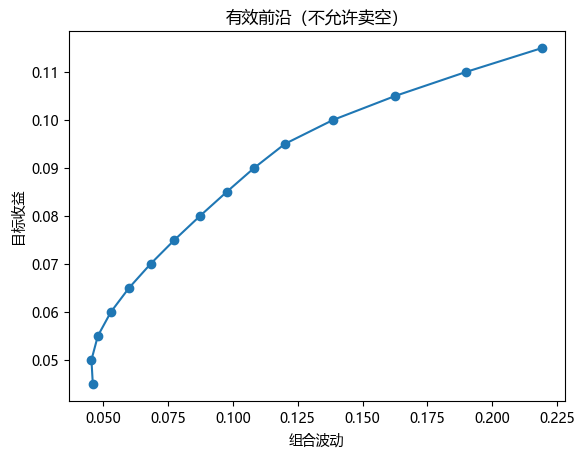

In [4]:

import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

mu = np.array([0.04, 0.08, 0.12])
S = np.diag([0.05 ** 2, 0.12 ** 2, 0.25 ** 2])

frontier = []
for target in np.linspace(0.045, 0.115, 15):
    cons = [
        {"type": "eq", "fun": lambda w: w.sum() - 1},
        {"type": "eq", "fun": lambda w: w @ mu - target},
    ]
    res = minimize(lambda w: w @ S @ w, x0=np.array([1 / 3] * 3),
                   bounds=[(0, 1)] * 3, constraints=cons, method="SLSQP")
    if res.success:
        frontier.append((target, np.sqrt(res.fun)))

frontier = np.array(frontier)
plt.plot(frontier[:, 1], frontier[:, 0], "o-")
plt.xlabel("组合波动")
plt.ylabel("目标收益")
plt.title("有效前沿（不允许卖空）")
plt.show()



**读数与应用**：前沿向右上方倾斜；目标收益越高，需要承担越大波动。若某个目标收益不可行（超出资产收益范围），求解会失败，前沿截断。

**常见错误**：

1. 把“前沿”当成“最优组合”。前沿是一组组合，选哪个还要看风险偏好。
2. 用样本协方差画前沿，再拿样本外检验；估计误差会让“最优”失效。
3. 忽略约束。无约束前沿可能要求大量卖空，实盘做不到。

**停下来想一想**：为什么样本协方差画的“最优前沿”在样本外常常失效？

<details><summary>对照你的思路</summary>

协方差矩阵和预期收益都是估计的，有误差；优化器会放大误差，把权重推到“估计出来的最优”角落。样本外这些误差变了，权重就失效。实务中常用收缩、风险模型、约束和稳健优化来缓解。

</details>

---



## 6. 梯度下降：没有解析解时怎么找

### 6.1 梯度

梯度是目标函数对每个变量的一阶偏导组成的向量：

$$\nabla f(w)=\left(\frac{\partial f}{\partial w_1},\dots,\frac{\partial f}{\partial w_n}\right).$$

它指向函数上升最快的方向；负梯度方向是下降最快的方向。

### 6.2 更新

$$w_{k+1}=w_k-\eta\nabla f(w_k).$$

**公式拆解**
- **符号**：$w_k$ 第 $k$ 步参数，$\eta$ 学习率，$\nabla f$ 梯度；$k$ 是迭代次数非时间。
- **结构**：沿负梯度走 $\eta$ 倍；二次目标 $f=\frac L2w^2$ 要 $0<\eta<2/L$ 才收敛。
- **代入**：$f=(w-2)^2,\eta=0.1,w_0=0$：$w_1=0.4,w_2=0.72$，误差每步乘 0.8。
- **边界**：$\eta>2/L$ 发散；$L=0$ 原地不动。
- **用途**：大规模 ML、在线更新；收敛不等于全局最优。

$\eta$ 是学习率。太大震荡/发散，太小收敛慢。

### 6.3 手算

$f(w)=(w-2)^2$，梯度 $2(w-2)$。从 $w=0$ 出发，$\eta=0.1$：

$$w_1=0-0.1\times(-4)=0.4,$$

$$w_2=0.4-0.1\times(-3.2)=0.72,$$

逐步靠近 2。

### 6.4 代码：梯度下降



In [5]:

w, lr = 0.0, 0.1
for step in range(20):
    grad = 2 * (w - 2)
    w = w - lr * grad
print("最终 w", round(w, 6))


最终 w 1.976942



**读数与应用**：凸二次函数上，梯度下降会收敛到 2；学习率太大时会来回震荡。真实组合优化通常用 SLSQP/内点法，梯度下降更多用于大规模机器学习。

**常见错误**：

1. 学习率太大，发散。
2. 忘记标准化特征，梯度尺度差异大，收敛慢。
3. 在非凸问题上把“收敛”当“全局最优”。

**停下来想一想**：为什么学习率太大会震荡？

<details><summary>对照你的思路</summary>

更新步长是 $\eta\times$ 梯度；$\eta$ 太大时，一步跨过最优点，下一步又跨回来，甚至越跨越远。对二次函数，稳定的条件是 $\eta<2/L$（$L$ 是最大曲率）；超过就发散。

</details>

---



## 7. 拉格朗日乘数与 KKT：约束的“影子价格”

### 7.1 等式约束

最小化 $f(x)$，约束 $g(x)=0$。拉格朗日函数：

$$L(x,\lambda)=f(x)+\lambda g(x).$$

**公式拆解**
- **符号**：$x$ 决策变量，$f$ 目标，$g=0$ 等式约束，$\lambda,\mu$ 乘子。
- **结构**：$L=f+\lambda g$，$\nabla f=-\lambda\nabla g$；KKT 加 $\mu\ge0$、$\mu h=0$。
- **代入**：$\min a^2+4b^2$ s.t. $a+b=1$：得 $a=0.8,b=0.2$，$f=0.8$，$\lambda=1.6$。
- **边界**：约束没咬住时 $\mu=0$；非凸时 KKT 只是必要。
- **用途**：解约束优化、读影子价格；$\lambda$ 是敏感度，不是最优值。

最优解满足：

$$\nabla_xL=0,\qquad g(x)=0.$$

$\lambda$ 是“约束的影子价格”：约束放松一单位，目标能改善多少。

### 7.2 手算

最小化 $a^2+4b^2$，约束 $a+b=1$：

$$L=a^2+4b^2+\lambda(1-a-b).$$

$$\frac{\partial L}{\partial a}=2a-\lambda=0,\qquad \frac{\partial L}{\partial b}=8b-\lambda=0.$$

所以 $a=4b$；代入 $a+b=1$，$b=0.2,a=0.8$。最小值 $0.64+0.16=0.8$，$\lambda=1.6$。

### 7.3 KKT

不等式约束 $h(x)\le0$ 时，条件变成：

- 平稳性：$\nabla f+\lambda\nabla g+\mu\nabla h=0$；
- 原始可行：$g=0,h\le0$；
- 对偶可行：$\mu\ge0$；
- 互补松弛：$\mu h=0$。

互补松弛的意思是：约束没起作用（$h<0$）时 $\mu=0$；约束起作用（$h=0$）时 $\mu$ 可以大于 0。

### 7.4 代码：解 KKT 线性系统



In [6]:

import numpy as np

# 未知数 a, b, lambda；方程：2a-lambda=0, 8b-lambda=0, a+b=1
A = np.array([[2.0, 0.0, -1.0],
              [0.0, 8.0, -1.0],
              [1.0, 1.0, 0.0]])
rhs = np.array([0.0, 0.0, 1.0])
print("a, b, lambda", np.linalg.solve(A, rhs).round(3))


a, b, lambda [0.8 0.2 1.6]



**读数与应用**：解出 $a=0.8,b=0.2,\lambda=1.6$。$\lambda=1.6$ 表示“预算放松一单位，目标最多改善 1.6”（局部）。影子价格在组合优化里对应“约束的边际价值”。

**常见错误**：

1. 忘记互补松弛。约束没起作用时，乘子应为 0。
2. 把 $\lambda$ 当“最优值”。它是敏感度，不是目标值。
3. 不等式方向写反。$h\le0$ 的乘子 $\mu\ge0$。

**停下来想一想**：如果预算约束从 1 放松到 1.1，最小目标会变成多少？

<details><summary>对照你的思路</summary>

一阶近似：$0.8-1.6\times0.1=0.64$。实际值要用新约束重算；影子价格只在一阶近似下成立。约束越大，非线性项越明显。

</details>

---



## 8. 动态规划：大单怎样拆成小单

### 8.1 贝尔曼递推

多期决策：

$$V_t(s)=\min_a\left[c_t(s,a)+V_{t+1}(s')\right].$$

$V_t(s)$ 是“从状态 $s$ 出发，剩余各期的最小成本”；$a$ 是当期动作；$s'$ 是下一期状态。

### 8.2 手算：两期执行

总共 4 手，分两期执行。前段执行 $a$ 手，成本 $a^2$；后段执行 $4-a$ 手，成本 $2(4-a)^2$。

| $a$ | 前段成本 | 后段成本 | 总成本 |
|---:|---:|---:|---:|
| 0 | 0 | 32 | 32 |
| 1 | 1 | 18 | 19 |
| 2 | 4 | 8 | 12 |
| 3 | 9 | 2 | 11 |
| 4 | 16 | 0 | 16 |

最优 $a=3$，总成本 11。**不是平均分 2+2**，因为后段成本更高，应该前段多做。

### 8.3 代码：枚举



In [7]:

for a in range(5):
    cost = a ** 2 + 2 * (4 - a) ** 2
    print("前段", a, "总成本", cost)


前段 0 总成本 32
前段 1 总成本 19
前段 2 总成本 12
前段 3 总成本 11
前段 4 总成本 16



**读数与应用**：动态规划的核心是“状态”和“递推”。状态要保留“影响未来成本的信息”（剩余手数、已执行量、库存、时间）；状态设计错了，递推就不对。

**常见错误**：

1. 只做单期最优，忽略未来成本。
2. 状态不完整，比如忘记剩余库存/时间。
3. 把“计划”当“可执行”。真实成交量、价格冲击会改变状态转移。

**停下来想一想**：如果后段成本更低，最优会怎么变？

<details><summary>对照你的思路</summary>

后段成本低，应该把更多执行放到后段，前段少做。比如后段成本系数从 2 降到 0.5，最优 $a$ 会向 0 移动。动态规划会自动权衡“当期成本”和“未来成本”。

</details>

---



## 9. 启发式优化：非凸、离散、组合爆炸

### 9.1 为什么需要

当变量是整数、有基数约束、目标非凸时，梯度/二次规划不适用。可选：

- 穷举（小规模）；
- 分支定界（中等规模）；
- 遗传算法、模拟退火、粒子群（大规模/黑箱）。

### 9.2 遗传算法

把候选解编码成“个体”，按目标选择父代，用交叉/变异产生下一代。它不保证全局最优，但能在复杂空间里找到“足够好”的解。

### 9.3 评价启发式

如果问题规模小，先穷举出真正最优，再量启发式漏了多少。**没有对照的启发式，不能宣称“最优”。**

### 9.4 代码：小规模穷举



In [8]:

import itertools

items = [("A", 2, 3), ("B", 3, 5), ("C", 4, 6)]  # 名称、成本、价值
budget = 6
best = None

for r in range(len(items) + 1):
    for combo in itertools.combinations(items, r):
        cost = sum(x[1] for x in combo)
        value = sum(x[2] for x in combo)
        if cost <= budget and (best is None or value > best[1]):
            best = (combo, value)

print("最优组合", best[0], "价值", best[1])


最优组合 (('A', 2, 3), ('C', 4, 6)) 价值 9



**读数与应用**：穷举给出真正最优；启发式要拿它做基准。规模变大时，穷举不可行，才需要分支定界/遗传算法。

**常见错误**：

1. 用启发式解小问题，却不和穷举比。
2. 把“跑了很多代”当“收敛到最优”。
3. 目标函数写错，优化器再强也没用。

**停下来想一想**：遗传算法适合“选 5 个因子”这种问题吗？

<details><summary>对照你的思路</summary>

可以，但要注意编码（0/1 向量）、约束修复（选多了要修）、评价函数（样本外/成本）。如果因子数不多（比如 20 选 5），穷举/分支定界可能更可靠；因子多、目标黑箱时，启发式才有优势。

</details>

---



## 10. 摩擦下的组合：理论最优为什么不能用

### 10.1 三类摩擦

1. **交易成本**：手续费、价差、冲击成本；
2. **换手/容量**：频繁调仓、资金规模；
3. **离散约束**：整数手数、最小变动、保证金。

### 10.2 把成本写进目标

$$ \min_w\ w^TSw+\lambda\,|w-w_0|_1.$$

**公式拆解**
- **符号**：$w$ 目标权重，$w_0$ 当前持仓，$|w-w_0|_1$ 单边换手，$\lambda$ 系数。
- **结构**：风险加线性成本 $\lambda|w-w_0|_1$；L1 折点产生不调仓区间。
- **代入**：$S=\mathrm{diag}(0.04,0.16),w_0=(0.5,0.5)$，$\lambda=0.05$：$w_1=0.55$，目标 $0.0495<0.05$。
- **边界**：$\lambda=0$ 退化为纯 QP；$\lambda$ 大时 $w\to w_0$。
- **用途**：控换手、纳入成本；不是手续费率。

$|w-w_0|_1$ 是换手（单边/双边要写清），$\lambda$ 是成本系数。$\lambda$ 越大，越不愿意调仓。

### 10.3 整数手数

连续权重解出来 0.37 手，实盘只能 0 或 1 手。四舍五入可能违反预算/风险；要用整数规划，或者“先连续、再取整、再检查约束”。

### 10.4 代码：换手惩罚



In [9]:

import numpy as np

w0 = np.array([0.5, 0.5])
S = np.array([[0.04, 0.006], [0.006, 0.09]])

for lam in [0.0, 0.01, 0.05]:
    best = None
    for w in np.linspace(0, 1, 101):
        weights = np.array([w, 1 - w])
        obj = weights @ S @ weights + lam * np.abs(weights - w0).sum()
        if best is None or obj < best[1]:
            best = (weights, obj)
    print("lambda", lam, "权重", best[0].round(3), "目标", round(best[1], 4))


lambda 0.0 权重 [0.71 0.29] 目标 0.0302
lambda 0.01 权重 [0.63 0.37] 目标 0.0336
lambda 0.05 权重 [0.5 0.5] 目标 0.0355



**读数与应用**：$\lambda=0$ 时，最优权重会偏离 0.5；$\lambda$ 增大，权重被拉回 0.5，因为调仓成本高。真实组合优化要把“成本系数”校准到实际价差/手续费/冲击成本。

**常见错误**：

1. 只算手续费，不算价差/冲击。成本被低估。
2. 用单边换手当双边。报告要写清口径。
3. 连续权重直接四舍五入，不检查预算/风险/保证金。

**停下来想一想**：为什么“理论最优”在实盘常常跑不过“简单等权”？

<details><summary>对照你的思路</summary>

理论最优依赖估计的预期收益/协方差；估计误差会被优化器放大，导致权重极端、换手高、成本大。等权不依赖估计，稳健、换手低，所以在样本外常常不差。优化不是越复杂越好，要看估计质量和成本。

</details>

---



## 本章小结

### 一张公式表

| 概念 | 公式 | 用途 |
|---|---|---|
| 优化问题 | $\min f(x)$ s.t. $x\in\mathcal X$ | 统一语言 |
| 凸函数 | $f(tx+(1-t)y)\le tf(x)+(1-t)f(y)$ | 局部=全局 |
| 线性规划 | $\min c^Tx$ s.t. $Ax\le b$ | 顶点解 |
| 二次规划 | $\min \frac12w^TSw$ | 均值-方差 |
| 有效前沿 | 给定收益的最小方差 | 组合选择 |
| 梯度下降 | $w_{k+1}=w_k-\eta\nabla f$ | 数值优化 |
| 拉格朗日 | $L=f+\lambda g$ | 约束/影子价格 |
| KKT | 平稳+可行+互补松弛 | 不等式约束 |
| 贝尔曼 | $V_t(s)=\min_a[c+V_{t+1}]$ | 多期执行 |
| 换手惩罚 | $w^TSw+\lambda|w-w_0|_1$ | 成本 |

### 八句话

1. 先写变量、目标、约束，再谈算法。
2. 凸问题的局部最小就是全局最小；整数/基数约束会破坏凸性。
3. 线性规划的最优通常在顶点。
4. 均值-方差是二次规划；协方差必须半正定。
5. 有效前沿是一组组合，不是“唯一最优”。
6. 梯度下降的学习率太大会震荡。
7. 拉格朗日乘子是约束的影子价格。
8. 理论最优要被成本、换手、整数手数“打折”。

---

## 本章习题

**1.** 最大化 $2A+3B$，约束 $A+B\le4,B\le2,A,B\ge0$。求最优解和最优值。

**2.** 两个资产方差 1 和 4，协方差 0，权重和为 1。求最小方差权重和最小方差。

**3.** 三个资产预期收益 4%、8%、12%，方差 $0.05^2,0.12^2,0.25^2$，协方差 0。不允许卖空，目标收益 10% 的最小方差组合大概会偏向哪个资产？

**4.** $f(w)=(w-2)^2$，从 $w=0$ 出发，$\eta=0.1$。求前两步。

**5.** 最小化 $a^2+4b^2$，约束 $a+b=1$。用拉格朗日求 $a,b,\lambda$。

**6.** 两期执行 4 手，前段成本 $a^2$，后段 $2(4-a)^2$。求最优 $a$。

**7.** 为什么“最多选 5 个因子”是非凸约束？

**8.** 组合优化里，换手惩罚 $\lambda|w-w_0|_1$ 的 $\lambda$ 变大，权重会怎样变？

<details><summary>参考答案</summary>

**1.** 顶点 $(2,2)$，值 10。

**2.** $\operatorname{Var}=w^2+4(1-w)^2$，导数 $10w-8=0$，$w=0.8$；最小方差 $0.8$。

**3.** 目标收益 10% 接近 8% 和 12% 之间，组合会偏向 12% 资产，但受低波动资产影响；具体权重由优化器算，通常不是全押 12%。

**4.** $w_1=0.4$；$w_2=0.72$。

**5.** $a=0.8,b=0.2,\lambda=1.6$。

**6.** $a=3$，总成本 11。

**7.** 0/1 选择变量的可行集是离散点集；两个可行解的连线可能选超过 5 个，违反约束。

**8.** $\lambda$ 变大，调仓成本权重变大，最优权重更靠近 $w_0$，换手下降。

</details>

---

## 参考资料

- Boyd, S. & Vandenberghe, L. *Convex Optimization*（凸优化标准教材）。
- Luenberger, D. G. *Investment Science*（均值-方差、有效前沿）。
- Grinold, R. C. & Kahn, R. N. *Active Portfolio Management*（组合优化实务）。
- Bertsimas, D. & Tsitsiklis, J. N. *Introduction to Linear Optimization*（线性规划/整数规划）。
